## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = True

SET_JPARAM = True
PSO_num = 2

RANDOM_SEED = 42

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [27]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso_sorted.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)
    # new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
    # frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[('cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[('cost', 'cost population dynamics 55 kPa erlotinib')]
    # new_param_pso_sort = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])
    new_params = frac_prolif_parameters_pso['model parameters']
    # Importing the parameters:
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[PSO_num]:
                model.parameters[key].value = new_params[key].iloc[PSO_num]
        except:
            print(key)
    model.parameters['omega'].value = 200

In [28]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [29]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

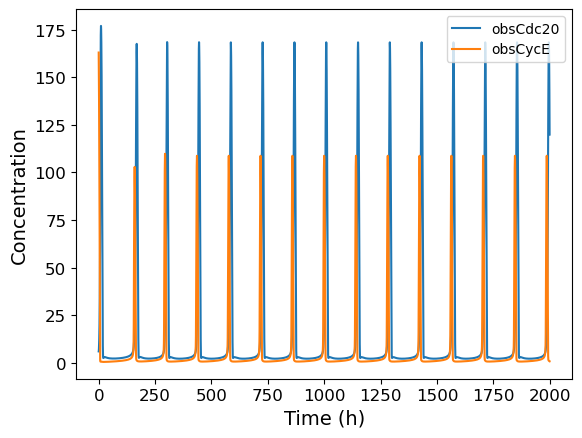

In [30]:
condition = "0.6 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False).run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,20000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

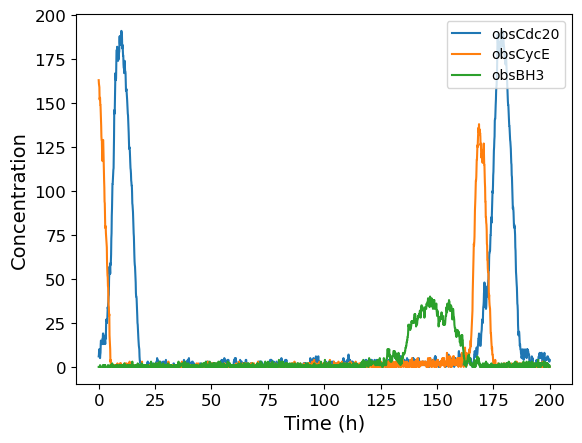

In [31]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False, seed=RANDOM_SEED)
observables=['obsCdc20', 'obsCycE', 'obsBH3']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [32]:
start_time = datetime.datetime.now()

init = 5
run_time = 120
observed_cells_time = 120
condition = "4 kPa erlotinib"

In [33]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

4 kPa erlotinib
elapsed time is 0:00:00.902571 minutes


In [34]:
population_history = population_df
parameters_sim = {}

In [35]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,3.010033,True,3.010033
1,0,36,0,Mitosis,3.010033,3.010033,41.237458,False,38.227425
2,0,37,36,End of experiment,41.237458,41.237458,120.000000,False,78.762542
3,1,1,Initial cell,Mitosis,0.000000,Initial cell,7.625418,True,7.625418
4,1,38,1,Mitosis,7.625418,7.625418,30.000000,False,22.374582
...,...,...,...,...,...,...,...,...,...
62,31,31,19,End of experiment,106.000162,106.000162,120.087848,False,14.087686
63,32,32,20,End of experiment,90.401338,90.401338,120.000000,False,29.598662
64,33,33,24,End of experiment,106.053512,106.053512,120.091092,False,14.037580
65,34,34,62,End of experiment,117.450576,117.450576,120.060447,False,2.609871


### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [36]:
model.parameters['CycDi_0'].value

0.0

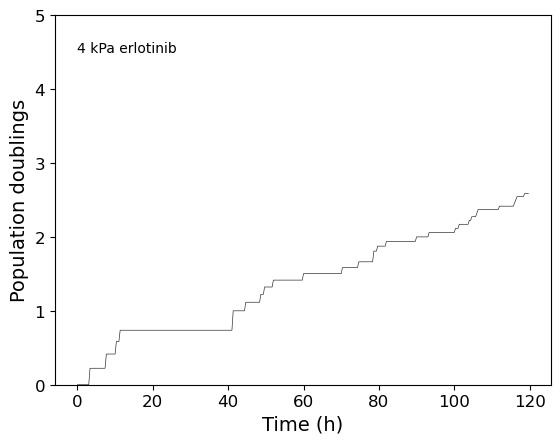

In [37]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

In [38]:
cells['molecules'][0]['obsBCL2'][0]

149.0

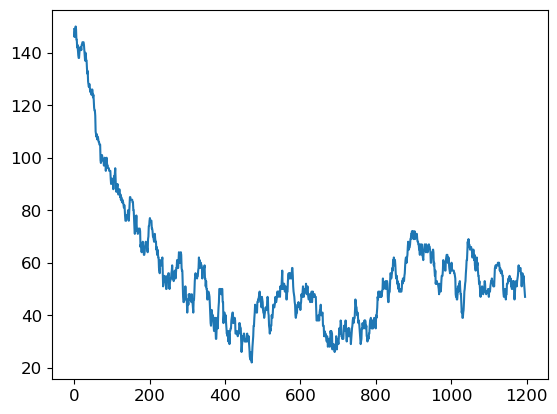

In [39]:
plt.plot(cells['molecules'][0]['obsBCL2'])

(0.0, 125.0)

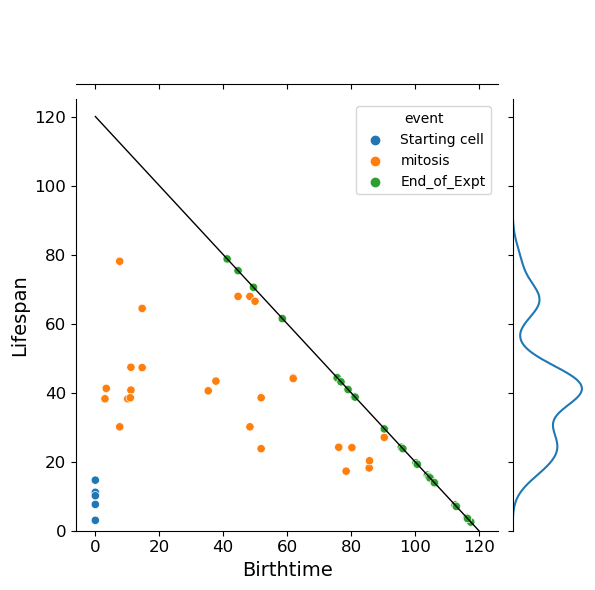

In [40]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [41]:
all_events_simulated

,event,Birthtime,Lifespan
0,Starting cell,0,3.010033
1,mitosis,3.010033,38.227425
2,End_of_Expt,41.237458,78.662207
3,Starting cell,0,7.625418
4,mitosis,7.625418,30.100334
...,...,...,...
62,End_of_Expt,106.202863,13.783635
63,End_of_Expt,90.401338,29.498328
64,End_of_Expt,106.053512,13.936590
65,End_of_Expt,117.450576,2.505476


(0.0, 125.0)

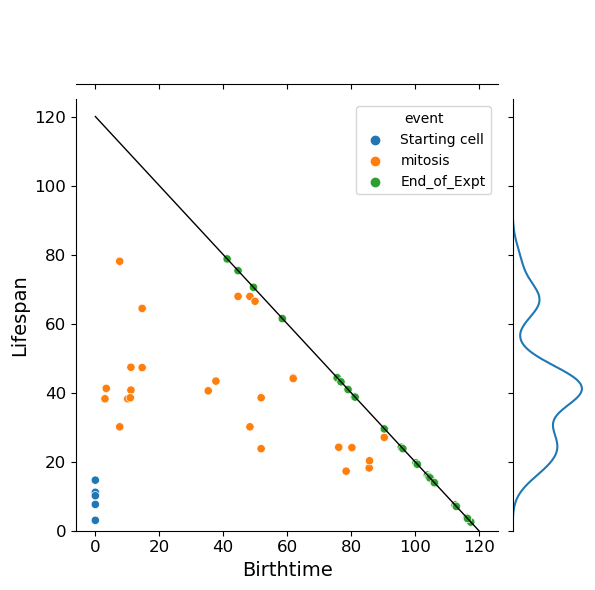

In [42]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [43]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [44]:
condition = "55 kPa erlotinib"

### Generate 

In [45]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 5

        if SET_JPARAM:
            fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_pso_{PSO_num}.csv')
            fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_pso_{PSO_num}.pkl')
        else:
            fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
            fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.pkl')
        
        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)

            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            if SAVE_CELL_DATA:
                print(f"Saving to {fn_cells}...")
                with open(fn_cells, 'wb') as f:
                    pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_0_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_0_param_pso_2.pkl...
elapsed time is 0:00:02.009871 minutes
4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_1_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_1_param_pso_2.pkl...
elapsed time is 0:00:03.948492 minutes
4 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_2_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_4 kPa erlotinib_2_param_pso_2.pkl...
elapsed time is 0:00:06.441898 minutes
4 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_0_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_4 kPa DMSO_0_param_pso_2.pkl...
elapsed time is 0:00:11.810602 minutes
4 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_1_param_pso_2.csv...
Saving to C:\Users\ole

In [46]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        if SET_JPARAM:
            fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_pso_{PSO_num}.csv')
            fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_pso_{PSO_num}.pkl')
        else:
            fn_cellcount = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
            fn_cells = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.pkl')

        if OVERWRITE or not os.path.exists(fn_cellcount) or not os.path.exists(fn_cells):
            (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, 
                                                                                   model, ECM_conditions, condition, 
                                                                                   sampled_parameter_names, thr=[0.26, 0.14], 
                                                                                   return_plot=False, bypass=True)
            print(f"Saving to {fn_cellcount}...")
            np.savetxt(fn_cellcount, cell_count, delimiter=',')
            if SAVE_CELL_DATA:
                print(f"Saving to {fn_cells}...")
                with open(fn_cells, 'wb') as f:
                    pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {fn_cellcount} and {fn_cells} already exist. Skipping...")
            
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_0_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa erlotinib_0_param_pso_2.pkl...
elapsed time is 0:00:51.933320 minutes
0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_1_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa erlotinib_1_param_pso_2.pkl...
elapsed time is 0:00:52.862595 minutes
0.6 kPa erlotinib
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_2_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa erlotinib_2_param_pso_2.pkl...
elapsed time is 0:00:53.538906 minutes
0.6 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_0_param_pso_2.csv...
Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa DMSO_0_param_pso_2.pkl...
elapsed time is 0:00:55.208755 minutes
0.6 kPa DMSO
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_1_param_pso_2.c

In [47]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200, 'PSO_2',
            SAVE_DIR)

0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
0.6 kPa erlotinib
Saving C:\Users\olesk\ECM_mod_output\IMTs_0.6 kPa erlotinib_PSO_2.csv, C:\Users\olesk\ECM_mod_output\G1s_0.6 kPa erlotinib_PSO_2.csv, and C:\Users\olesk\ECM_mod_output\SMs_0.6 kPa erlotinib_PSO_2.csv...
0.6 kPa DMSO
0.6 kPa DMSO
Saving C:\Users\olesk\ECM_mod_output\IMTs_0.6 kPa DMSO_PSO_2.csv, C:\Users\olesk\ECM_mod_output\G1s_0.6 kPa DMSO_PSO_2.csv, and C:\Users\olesk\ECM_mod_output\SMs_0.6 kPa DMSO_PSO_2.csv...
4 kPa erlotinib
4 kPa erlotinib
Saving C:\Users\olesk\ECM_mod_output\IMTs_4 kPa erlotinib_PSO_2.csv, C:\Users\olesk\ECM_mod_output\G1s_4 kPa erlotinib_PSO_2.csv, and C:\Users\olesk\ECM_mod_output\SMs_4 kPa erlotinib_PSO_2.csv...
4 kPa DMSO
Saving C:\Users\olesk\ECM_mod_output\IMTs_4 kPa DMSO_PSO_2.csv, C:\Users\olesk\ECM_mod_output\G1s_4 kPa DMSO_PSO_2.csv, and C:\